## Homework4 Jiayan Wang

# SIR Model Simulation

The SIR model divides a normalized population into three groups:

- $S(t)$: susceptible individuals
- $I(t)$: infected individuals
- $R(t)$: recovered individuals

In this simulation, the total population is normalized to 1. Therefore, $S(t)$, $I(t)$, and $R(t)$ represent population fractions rather than actual population numbers.

The SIR model is given by

$$
\frac{dS}{dt}=-\beta SI
$$

$$
\frac{dI}{dt}=\beta SI-\gamma I
$$

$$
\frac{dR}{dt}=\gamma I
$$

The total population is conserved:

$$
S(t)+I(t)+R(t)=1.
$$

The initial conditions are

$$
S(0)=0.99,\qquad I(0)=0.01,\qquad R(0)=0.
$$

Here, $\beta$ is the transmission rate and $\gamma$ is the recovery rate.

The basic reproduction number is

$$
R_0=\frac{\beta}{\gamma}.
$$

If the initial infected population is small, the infected population initially increases when

$$
\beta S(0)>\gamma.
$$

Therefore, the epidemic threshold for the transmission rate is

$$
\beta_c=\frac{\gamma}{S(0)}.
$$

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

## Define the SIR model

In [3]:
def sir_model(t, y, beta, gamma):
    S, I, R = y
    
    dSdt = -beta * S * I
    dIdt = beta * S * I - gamma * I
    dRdt = gamma * I
    
    return [dSdt, dIdt, dRdt]


def simulate_sir(beta, gamma, days=160):
    time = np.linspace(0, days, 1000)
    
    solution = solve_ivp(
        sir_model,
        [0, days],
        [0.99, 0.01, 0],
        args=(beta, gamma),
        t_eval=time
    )
    
    return time, solution.y[0], solution.y[1], solution.y[2]

## Two Parameter Cases

We compare two cases:

- Case 1: $\beta=0.3$, $\gamma=0.1$, so $R_0=3$
- Case 2: $\beta=0.5$, $\gamma=0.2$, so $R_0=2.5$

The second case has a higher transmission rate, so the infection is expected to spread faster.

In [5]:
cases = [
    (0.3, 0.1, "Case 1"),
    (0.05, 0.1, "Case 2")
]

results = {}

for beta, gamma, name in cases:
    t, S, I, R = simulate_sir(beta, gamma)
    results[name] = (t, S, I, R)

## SIR curves for the two cases

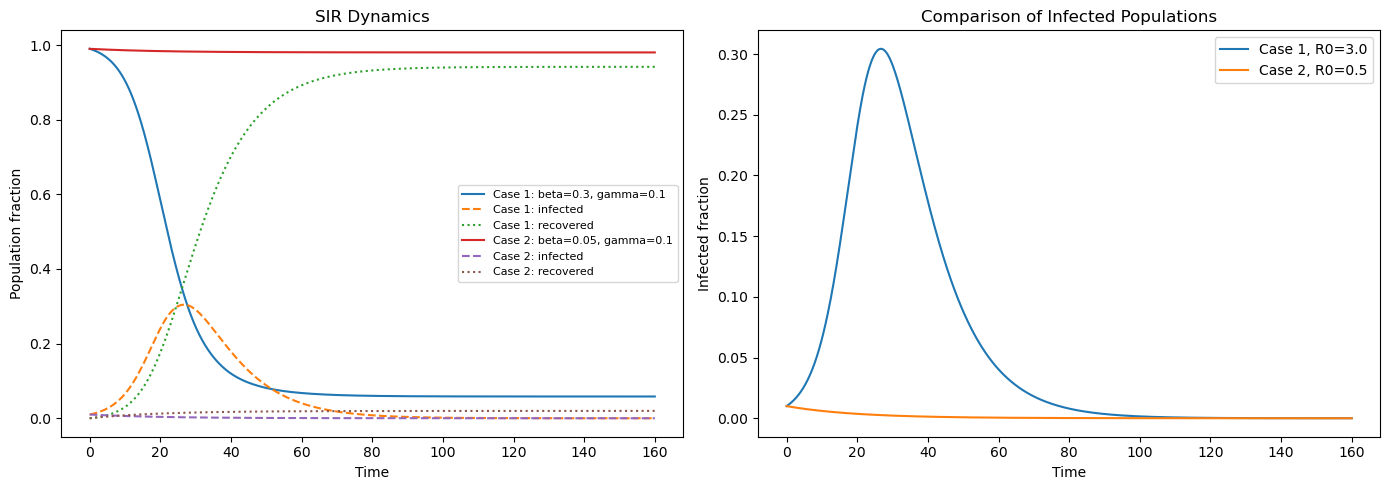

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for beta, gamma, name in cases:
    t, S, I, R = results[name]
    
    axes[0].plot(t, S, label=f"{name}: beta={beta}, gamma={gamma}")
    axes[0].plot(t, I, "--", label=f"{name}: infected")
    axes[0].plot(t, R, ":", label=f"{name}: recovered")
    
    axes[1].plot(
        t,
        I,
        label=f"{name}, R0={beta/gamma:.1f}"
    )

axes[0].set_title("SIR Dynamics")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Population fraction")
axes[0].legend(fontsize=8)

axes[1].set_title("Comparison of Infected Populations")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Infected fraction")
axes[1].legend()

plt.tight_layout()
plt.show()

## S-I Phase Curves

The phase curve shows the relationship between the susceptible population \(S\) and the infected population \(I\).

The trajectory starts with a high susceptible fraction and a small infected fraction. 
As the epidemic develops, the infected fraction increases. 
After reaching a peak, the infected fraction decreases because the susceptible population becomes smaller.

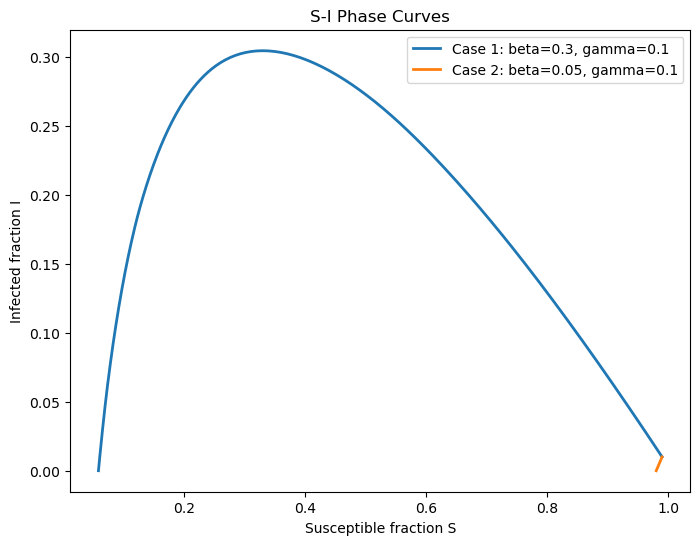

In [7]:
plt.figure(figsize=(8, 6))

for beta, gamma, name in cases:
    t, S, I, R = results[name]
    
    plt.plot(
        S,
        I,
        linewidth=2,
        label=f"{name}: beta={beta}, gamma={gamma}"
    )

plt.xlabel("Susceptible fraction S")
plt.ylabel("Infected fraction I")
plt.title("S-I Phase Curves")
plt.legend()
plt.show()

## Discussion

The two cases illustrate the epidemic threshold in the SIR model.

In Case 1, $\beta=0.3$ and $\gamma=0.1$. Since

$$
R_0=\frac{\beta}{\gamma}=3>1,
$$

the infected population initially increases. The epidemic develops, reaches an infection peak, and then declines as the susceptible population decreases.

In Case 2, $\beta=0.05$ and $\gamma=0.1$. In this case,

$$
R_0=\frac{\beta}{\gamma}=0.5<1.
$$

Also,

$$
\beta<\beta_c\approx 0.101.
$$

Therefore, the infected population decreases from the beginning, and the outbreak does not develop into a large epidemic.

This comparison shows that the transmission rate must be sufficiently large relative to the recovery rate for an epidemic to grow. The critical condition is determined by

$$
\beta S(0)>\gamma.
$$

If this condition is not satisfied, infected individuals recover faster than new infections are generated.